# Cyclic graph example

This page is an end-to-end workflow for a **cyclic** knowledge graph
represented as an edgelist: a prior with a cycle, a path that leads
from a node back to itself. You parse it, train a small model, and
interpret named nodes.

Read [Feedforward example](../feedforward-example/) first. That tutorial
is a feedforward `parse_layered()` neural network on a [directed acyclic
graph](../concepts/#dag) (DAG). This page is what changes when the graph
has a cycle.

What you get here:

- a tiny graph where two hidden nodes feed each other and form a
  cycle
- `parse_adjacency()`, which allows cycles and self-loops
- why `parse_layered()` cannot parse this graph (it needs a DAG)
- one shared `MaskedLinear` over all nodes, applied a fixed
  number of steps so a signal can travel around the cycle
- training on simulated data, then Captum scores on named nodes
- controls that switch which input is informative, including
  an input that reaches the output only along an edge of the cycle
- an edgelist for a cycle that returns to a measured gene, with
  the measurement kept as an input node

A cycle has no depth, so there are no layers to apply in order. Your
`forward()` is ordinary PyTorch instead: it applies one shared
`MaskedLinear` over the full [state vector](../concepts/#state-vector),
a single vector over all nodes, for a fixed number of steps, and writes
the input values in before each step. Weights are shared across steps.
`kpnn2` does not unroll time or pick the step count.

Every step sees the same `x`, so this is a cyclic neural network on a
static feature table, not a sequence model. It is not a recurrent
neural network (RNN) cell such as a long short-term memory (LSTM) or a
gated recurrent unit (GRU). For a changing `x_t`, see
[Time-series example](../time-series-example/). The model also does not
run until the values stop changing: it stops after the number of steps
you choose.

In [ ]:
import random

import numpy as np
import pandas as pd
import seaborn as sns
import torch
from graphviz import Digraph
from IPython.display import display
from matplotlib import pyplot as plt
from torch import nn

import kpnn2

In [ ]:
from matplotlib_inline.backend_inline import (
    set_matplotlib_formats,
)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

set_matplotlib_formats(
    "svg",
    bbox_inches=None,
)
_FONT_SIZE = 14
_FIG_W = 7.0
_plot_rc = {
    "font.size": _FONT_SIZE,
    "axes.titlesize": _FONT_SIZE,
    "axes.labelsize": _FONT_SIZE,
    "xtick.labelsize": _FONT_SIZE,
    "ytick.labelsize": _FONT_SIZE,
    "legend.fontsize": _FONT_SIZE,
    "legend.title_fontsize": _FONT_SIZE,
    "lines.linewidth": 1.0,
    "font.family": "Liberation Sans",
    "text.color": "black",
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.edgecolor": "black",
    "axes.grid": False,
    "axes.facecolor": "none",
    "figure.facecolor": "none",
    "savefig.facecolor": "none",
    "savefig.edgecolor": "none",
    "svg.fonttype": "none",
}
plt.rcParams.update(_plot_rc)
sns.set_theme(
    style="ticks",
    rc=_plot_rc,
)


def _new_fig(height):
    return plt.figure(figsize=(_FIG_W, height))


def _style_ax(ax):
    ax.tick_params(labelsize=_FONT_SIZE)
    ax.title.set_fontsize(_FONT_SIZE)
    ax.xaxis.label.set_size(_FONT_SIZE)
    ax.yaxis.label.set_size(_FONT_SIZE)
    ax.set_facecolor("none")
    ax.grid(False)

## Define the graph

This is the smallest graph in which a cycle matters. Two
hidden nodes feed each other, and each has its own input
feature:

- `input_signal` is the input to `node_a`
- `input_noise` is the input to `node_b`
- `node_a` and `node_b` form a cycle
- `node_a` connects to the output node `output`

The edgelist format is the one `parse_layered()` also takes: a
`source` column and a `target` column, nothing else, each row an
edge in the direction of computation. `parse_adjacency()`
additionally allows self-loops (a row where `source == target`),
which this graph does not use.

The first walkthrough treats `input_signal` as the only
informative feature. A later section repeats the same
architecture under positive and negative controls that vary which
inputs carry signal.


In [ ]:
# Edgelist code: the prior as a source/target DataFrame, one row per edge

edgelist = pd.DataFrame(
    {
        "source": [
            "input_signal",
            "input_noise",
            "node_a",
            "node_b",
            "node_a",
        ],
        "target": [
            "node_a",
            "node_b",
            "node_b",
            "node_a",
            "output",
        ],
    }
)

edgelist

,source,target
0,input_signal,node_a
1,input_noise,node_b
2,node_a,node_b
3,node_b,node_a
4,node_a,output


In [ ]:
try:
    kpnn2.parse_layered(edgelist)
except kpnn2.Kpnn2Error as error:
    print(error)

Edgelist contains a cycle. Only DAGs are supported. Unranked nodes: node_a, node_b, output.


The message names the nodes `parse_layered()` could not rank by
depth: `node_a` and `node_b`, which sit on the cycle, and `output`,
which reads from it. `parse_adjacency()` ranks no node, so the same
edgelist parses:

In [ ]:
spec = kpnn2.parse_adjacency(edgelist)

spec.nodes, spec.input_nodes, spec.hidden_nodes, spec.output_nodes

(('input_noise', 'input_signal', 'node_a', 'node_b', 'output'),
 ('input_noise', 'input_signal'),
 ('node_a', 'node_b'),
 ('output',))

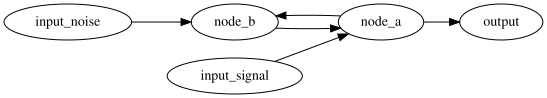

In [ ]:
# Plotting code: draw the edgelist with Graphviz

dot = Digraph()
dot.attr(rankdir="LR")

for node_name in spec.nodes:
    dot.node(node_name, node_name)

for row in edgelist.itertuples(index=False):
    dot.edge(str(row.source), str(row.target))

dot

## Shared masked update, unrolled for a fixed number of steps

The model is one layer applied several times. Each application
of that layer propagates values one edge along the graph, so two
applications carry a value from `node_a` around the cycle and
back.

Drawn with one column per step, three steps look like this. Each
arrow is one edge, from the state one step leaves to the step that
reads it, so the cycle `node_a ⇄ node_b` becomes the crossing
between columns. Dashed boxes are the input values `forward()`
writes in before the next step.
[How a cycle runs](../unrolling-a-cycle/) goes through every
computation of this model, step by step, with hand-set weights.

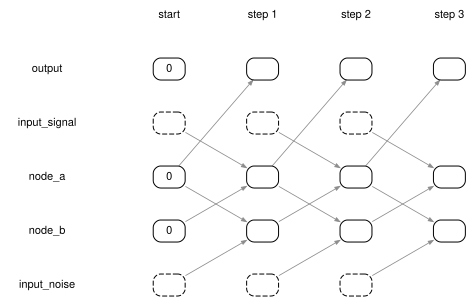

In [ ]:
_ROWS = [
    "output",
    "input_signal",
    "node_a",
    "node_b",
    "input_noise",
]
_N_DRAWN_STEPS = 3

unrolled = Digraph(engine="neato")
unrolled.attr(
    splines="true",
    outputorder="edgesfirst",
)
unrolled.attr(
    "node",
    fontname="Helvetica",
    fontsize="11",
    shape="box",
    style="rounded",
    height="0.3",
    width="0.45",
    margin="0.04,0.02",
)
unrolled.attr(
    "edge",
    color="#8c8c8c",
    arrowsize="0.5",
    penwidth="0.8",
)
for row, name in enumerate(_ROWS):
    unrolled.node(
        f"label_{name}",
        name,
        shape="plaintext",
        pos=f"-0.4,{-0.75 * row}!",
        width="1.2",
    )
for step in range(_N_DRAWN_STEPS + 1):
    unrolled.node(
        f"head_{step}",
        "start" if step == 0 else f"step {step}",
        shape="plaintext",
        pos=f"{1.3 * (step + 1)},0.75!",
    )
    for row, name in enumerate(_ROWS):
        is_input = name in spec.input_nodes
        if is_input and step == _N_DRAWN_STEPS:
            continue
        unrolled.node(
            f"{name}_{step}",
            "0" if step == 0 and not is_input else "",
            pos=f"{1.3 * (step + 1)},{-0.75 * row}!",
            style="rounded,dashed" if is_input else "rounded",
        )
for step in range(1, _N_DRAWN_STEPS + 1):
    for source, target in edgelist.itertuples(index=False):
        unrolled.edge(
            f"{source}_{step - 1}",
            f"{target}_{step}",
        )
unrolled

`parse_adjacency()` already did the structural work:

1. named node sets, with inputs at in-degree 0 and outputs at
   out-degree 0: `spec.input_nodes`, `spec.hidden_nodes`,
   `spec.output_nodes`
2. [packed indices](../concepts/#packed-indices) over `spec.nodes` —
   `source_index` / `target_index`, one entry per edge;
   `spec.to_mask()` is the dense square for this small graph
3. where the inputs and outputs sit inside that state vector:
   `spec.input_index`, `spec.output_index`

The rest is ordinary PyTorch:

4. wrap `spec.to_mask()` in `MaskedLinear`
5. apply it for a fixed number of steps, writing the input
   columns in with `index_copy` before each step
6. read the output nodes and apply a linear head

This graph is small, so `MaskedLinear` is appropriate. See
[PackedLinear](../packed_linear/) when `n_nodes` is large
enough that the square would hurt RAM.

Writing the inputs in is required, not cosmetic. No edge enters an
input node, so the layer has nothing to compute an input value from:
the input rows of `to_mask()` are empty. The measured values exist in
the state vector only where `forward()` writes them.

You interpret the model at those unrolled steps. Captum's layer
methods score the output of one module, and `self.core` runs at every
step, so it cannot single out one step. Each step's new state
therefore passes through its own `nn.Identity`, a tap that Captum can
hook. The taps hold no weights: every step uses the same `self.core`,
a normal child of the module.

The model runs three steps. Three is the smallest step count at which
both inputs reach `output`: a value moves one edge per step, and the
path from `input_noise`, `input_noise → node_b → node_a → output`, has
three edges.

The step has no activation. `output` is the only
[unit](../concepts/#unit) the head reads, and a ReLU on it passes no
gradient once it sits below zero for every sample, so training
stalls. When you add an activation, put the module between
`self.core` and the tap, as in
[Layered vs. unlayered](../layered_vs_adjacency/#how-you-compute).

In [ ]:
class CyclicNet(nn.Module):
    def __init__(
        self,
        spec: kpnn2.AdjacencySpec,
        n_steps: int,
    ):
        super().__init__()
        self.spec = spec
        self.core = kpnn2.MaskedLinear(spec.to_mask())
        self.register_buffer(
            "input_index",
            torch.as_tensor(spec.input_index),
        )
        self.taps = nn.ModuleList([nn.Identity() for _ in range(n_steps)])
        self.head = nn.Linear(1, 1)

    def forward(self, x):
        state = x.new_zeros(
            x.shape[0],
            self.core.in_features,
        )
        for tap in self.taps:
            state = state.index_copy(
                -1,
                self.input_index,
                x,
            )
            state = tap(self.core(state))
        output = state[:, self.spec.output_index]
        return self.head(output)

In [ ]:
n_steps = 3
model = CyclicNet(
    spec,
    n_steps=n_steps,
)
spec.nodes, spec.input_index, len(model.taps)

(('input_noise', 'input_signal', 'node_a', 'node_b', 'output'), (0, 1), 3)

## Simulate data, align features, and train

The data are simulated so the right answer is known: the two
classes differ by a shift on `input_signal`, while `input_noise`
has the same distribution in both. `align_inputs()` then returns
a column index into the feature names. Train and test share that
index here because both tables use the same column order.


In [ ]:
# Simulation code: class 0 shifts informative inputs by -1.5, class 1 by +1.5
def simulate_binary_data(
    n_per_class,
    feature_names,
    informative_features,
    rng,
):
    n_features = len(feature_names)
    n_samples = 2 * n_per_class
    x = rng.normal(
        0.0,
        1.0,
        size=(n_samples, n_features),
    )
    y = np.array([0] * n_per_class + [1] * n_per_class)
    informative_idx = [
        feature_names.index(name) for name in informative_features
    ]
    for class_value, shift in enumerate([-1.5, 1.5]):
        class_mask = y == class_value
        for feature_idx in informative_idx:
            x[class_mask, feature_idx] += shift
    x_df = pd.DataFrame(
        x,
        columns=feature_names,
    )
    y_series = pd.Series(y, name="label")
    return x_df, y_series

In [ ]:
# Simulation code: draw train and test sets, only input_signal informative

rng = np.random.default_rng(42)

x_train_df, y_train = simulate_binary_data(
    n_per_class=80,
    feature_names=list(spec.input_nodes),
    informative_features=["input_signal"],
    rng=rng,
)

x_test_df, y_test = simulate_binary_data(
    n_per_class=40,
    feature_names=list(spec.input_nodes),
    informative_features=["input_signal"],
    rng=rng,
)

x_train_df.head()

,input_noise,input_signal
0,0.304717,-2.539984
1,0.750451,-0.559435
2,-1.951035,-2.802180
3,0.127840,-1.816243
4,-0.016801,-2.353044


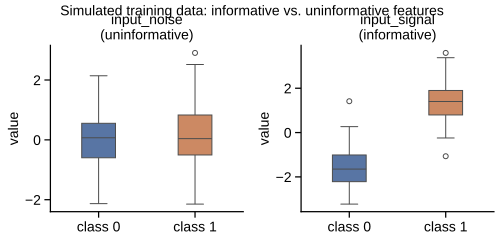

In [ ]:
# Plotting code: boxplots of each input feature by class

plot_df = x_train_df.copy()
plot_df["label"] = y_train.values
plot_df["class"] = plot_df["label"].map({0: "class 0", 1: "class 1"})

long_df = plot_df.melt(
    id_vars=["label", "class"],
    value_vars=list(spec.input_nodes),
    var_name="feature",
    value_name="value",
)

feature_type_map = {
    "input_signal": "informative",
    "input_noise": "uninformative",
}
long_df["feature_type"] = long_df["feature"].map(feature_type_map)

n_cols = 2
g = sns.catplot(
    data=long_df,
    x="class",
    y="value",
    col="feature",
    col_wrap=n_cols,
    hue="class",
    kind="box",
    width=0.35,
    sharey=False,
    height=_FIG_W / n_cols,
    aspect=1.0,
    legend=False,
)
g.fig.set_size_inches(_FIG_W, g.fig.get_figheight())
g.fig.suptitle(
    "Simulated training data: informative vs. uninformative features",
    fontsize=_FONT_SIZE,
    y=0.98,
)
g.fig.subplots_adjust(
    top=0.82,
    bottom=0.16,
    left=0.1,
    right=0.98,
    wspace=0.3,
)
for ax, feature in zip(g.axes.flat, spec.input_nodes):
    feature_type = feature_type_map[feature]
    ax.set_title(f"{feature}\n({feature_type})")
    ax.set_xlabel("")
    ax.set_ylabel("value")
    _style_ax(ax)
g.fig.patch.set_facecolor("none")
plt.show()

In [ ]:
# Train and test share column order, so one col is valid.
col = kpnn2.align_inputs(x_train_df.columns, spec)
x_train = torch.as_tensor(
    x_train_df.to_numpy()[:, col],
    dtype=torch.float32,
)
x_test = torch.as_tensor(
    x_test_df.to_numpy()[:, col],
    dtype=torch.float32,
)

y_train_tensor = torch.tensor(
    y_train.values.reshape(-1, 1),
    dtype=torch.float32,
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.05,
)
loss_fn = nn.BCEWithLogitsLoss()

n_epochs = 100
loss_history = []
model.train()
for _ in range(n_epochs):
    optimizer.zero_grad()
    logits = model(x_train)
    loss = loss_fn(logits, y_train_tensor)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

print(
    "Loss before first update:",
    round(loss_history[0], 4),
)
print(
    "Loss after final update: ",
    round(loss_history[-1], 4),
)

Loss before first update: 0.7995
Loss after final update:  0.1255


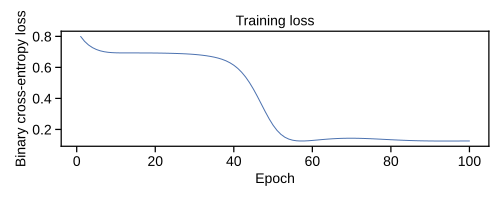

In [ ]:
# Plotting code: training loss per epoch

_new_fig(2.8)
plt.plot(
    range(1, n_epochs + 1),
    loss_history,
    linewidth=1,
)
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training loss")
plt.tight_layout()
plt.show()

## Interpret nodes

Only `input_signal` is informative in this first walkthrough, so
`node_a` is the expected answer.

Captum `LayerConductance` scores each unrolled step. Then
`map_node_attributions()` labels the `(batch, n_nodes)` tensor
as xarray with the full state-vector names. Convert with
`.to_pandas()` for the tables below. `kpnn2` does not import
Captum. For the mapper itself, see
[Attributions by node name](../map-node-attributions/).

There is no `layer=` argument here. An `AdjacencySpec` has no
depths, so the node axis is the whole state vector (`spec.nodes`)
and the result carries no `layer` coordinate.


In [ ]:
from captum.attr import LayerConductance

model.eval()
node_attr_by_site = {}
for index, tap in enumerate(
    model.taps,
    start=1,
):
    conductor = LayerConductance(
        model,
        tap,
    )
    attributions = conductor.attribute(
        x_test,
        target=0,
    )
    node_attr_by_site[f"step_{index}"] = kpnn2.map_node_attributions(
        attributions=attributions,
        spec=spec,
    ).to_pandas()

list(node_attr_by_site.keys())

['step_1', 'step_2', 'step_3']

In [ ]:
for site_id, site_df in node_attr_by_site.items():
    print(site_id)
    display(site_df.head())

step_1


node,input_noise,input_signal,node_a,node_b,output
observation,,,,,
0,0.0,0.0,0.0,0.151826,0.0
1,0.0,0.0,0.0,0.227296,0.0
2,0.0,0.0,0.0,0.353321,0.0
3,0.0,0.0,0.0,-0.305076,0.0
4,0.0,0.0,0.0,-0.227444,0.0


step_2


node,input_noise,input_signal,node_a,node_b,output
observation,,,,,
0,0.0,0.0,-5.456128,0.0,0.0
1,0.0,0.0,-2.257600,0.0,0.0
2,0.0,0.0,-2.198228,0.0,0.0
3,0.0,0.0,-5.502719,0.0,0.0
4,0.0,0.0,-6.922154,0.0,0.0


step_3


node,input_noise,input_signal,node_a,node_b,output
observation,,,,,
0,0.0,0.0,0.0,0.0,-5.456128
1,0.0,0.0,0.0,0.0,-2.257600
2,0.0,0.0,0.0,0.0,-2.198228
3,0.0,0.0,0.0,0.0,-5.502719
4,0.0,0.0,0.0,0.0,-6.922154


Each table has one nonzero column, and it moves one edge closer to
`output` with every step: `node_b` at step 1, `node_a` at step 2,
`output` at step 3. The head reads `output` after the last step. Every
step recomputes every node from the state after the previous step, so
a node's value at a step reaches the head only along a path with
exactly as many edges as steps remain:

- After step 1, two steps remain. `node_b → node_a → output` has two
  edges. `node_a` has no two-edge path to `output`, so it scores zero.
- After step 2, one step remains, and only `node_a` feeds `output`.
- After step 3, the head reads `output` itself.

The input columns are zero at every step. No edge enters an input
node, so the layer computes nothing from the data in those slots, and
`forward()` overwrites them before the next step reads them.

So a node can matter at one step and not at another, and the scores
are signed. The summary below therefore keeps, per node, the signed
value from the step of largest magnitude, and takes `.abs()` only for
ranking. It covers the **hidden nodes** (`node_a`, `node_b`).

In [ ]:
def peak_hidden_summary(site_tables, hidden_nodes):
    stacked = np.stack(
        [table[hidden_nodes].to_numpy() for table in site_tables],
        axis=0,
    )
    pick = np.abs(stacked).argmax(axis=0)
    n_batch, n_hidden = pick.shape
    values = np.empty((n_batch, n_hidden))
    rows = np.arange(n_batch)
    for j in range(n_hidden):
        values[:, j] = stacked[
            pick[:, j],
            rows,
            j,
        ]
    return pd.DataFrame(
        values,
        columns=hidden_nodes,
    )


node_importance = peak_hidden_summary(
    list(node_attr_by_site.values()),
    list(spec.hidden_nodes),
)
node_importance.head()

,node_a,node_b
0,-5.456128,0.151826
1,-2.257600,0.227296
2,-2.198228,0.353321
3,-5.502719,-0.305076
4,-6.922154,-0.227444


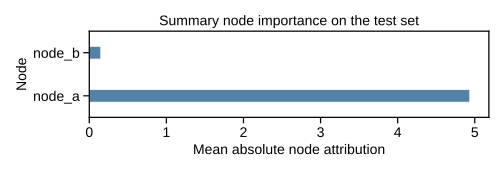

In [ ]:
# Plotting code: mean absolute peak attribution per hidden node

summary_a_only = (
    node_importance.abs()
    .mean(axis=0)
    .sort_values(ascending=True)
    .rename("mean_abs_attribution")
    .reset_index()
    .rename(columns={"index": "node"})
)

_new_fig(2.4)
sns.barplot(
    data=summary_a_only,
    x="mean_abs_attribution",
    y="node",
    color="steelblue",
    width=0.3,
)
plt.xlabel("Mean absolute node attribution")
plt.ylabel("Node")
plt.title("Summary node importance on the test set")
plt.tight_layout()
plt.show()

## Positive and negative controls

The walkthrough above recovers importance on `node_a` when only
`input_signal` is informative. `node_b` scores small but not zero. It
does reach `output`, through the edge `node_b → node_a`, but
its input, `input_noise`, carries no class signal.

That contrast is incomplete: it does not show whether importance
tracks the signal or the architecture, nor what happens when the
other input carries signal, when both do, or when neither does.

Hidden nodes and the output stay fixed; each of the four cases
below rebuilds the edgelist and names its inputs by role:

| Case | Input → `node_a` | Input → `node_b` | Expected |
| --- | --- | --- | --- |
| A only | `input_signal` | `input_noise` | `a` high, `b` low |
| Both | `input_signal_a` | `input_signal_b` | both high |
| B only | `input_noise` | `input_signal` | both high |
| Neither | `input_noise_a` | `input_noise_b` | both low |

A only reuses the walkthrough results above. The other three cases
each train a fresh `CyclicNet` on their own edgelist and simulated
data, with the same three steps and training settings.

In [ ]:
# Control code: helpers and runs for the four cases in the table above
def plot_graph(edgelist, input_a, input_b):
    dot = Digraph()
    dot.attr(rankdir="LR")
    for node_name in [input_a, input_b]:
        dot.node(node_name, node_name)
    for node_name in ["node_a", "node_b"]:
        dot.node(node_name, node_name)
    dot.node("output", "output")
    for row in edgelist.itertuples(index=False):
        dot.edge(
            str(row.source),
            str(row.target),
        )
    return dot


def make_edgelist(input_a, input_b):
    return pd.DataFrame(
        {
            "source": [
                input_a,
                input_b,
                "node_a",
                "node_b",
                "node_a",
            ],
            "target": [
                "node_a",
                "node_b",
                "node_b",
                "node_a",
                "output",
            ],
        }
    )


def run_cyclic_case(
    edgelist,
    informative_features,
    n_epochs=100,
):
    torch.manual_seed(42)
    rng = np.random.default_rng(42)
    case_spec = kpnn2.parse_adjacency(edgelist)
    case_model = CyclicNet(
        case_spec,
        n_steps=n_steps,
    )
    x_train_df, y_train = simulate_binary_data(
        n_per_class=80,
        feature_names=list(case_spec.input_nodes),
        informative_features=informative_features,
        rng=rng,
    )
    x_test_df, y_test = simulate_binary_data(
        n_per_class=40,
        feature_names=list(case_spec.input_nodes),
        informative_features=informative_features,
        rng=rng,
    )
    # Same feature_names on train and test, so one col is valid.
    col = kpnn2.align_inputs(
        x_train_df.columns,
        case_spec,
    )
    x_train = torch.as_tensor(
        x_train_df.to_numpy()[:, col],
        dtype=torch.float32,
    )
    x_test = torch.as_tensor(
        x_test_df.to_numpy()[:, col],
        dtype=torch.float32,
    )
    y_train_tensor = torch.tensor(
        y_train.values.reshape(-1, 1),
        dtype=torch.float32,
    )
    optimizer = torch.optim.Adam(
        case_model.parameters(),
        lr=0.05,
    )
    loss_fn = nn.BCEWithLogitsLoss()
    loss_history = []
    case_model.train()
    for _ in range(n_epochs):
        optimizer.zero_grad()
        logits = case_model(x_train)
        loss = loss_fn(logits, y_train_tensor)
        loss.backward()
        optimizer.step()
        loss_history.append(loss.item())
    case_model.eval()
    site_tables = []
    for tap in case_model.taps:
        conductor = LayerConductance(
            case_model,
            tap,
        )
        attributions = conductor.attribute(
            x_test,
            target=0,
        )
        site_tables.append(
            kpnn2.map_node_attributions(
                attributions=attributions,
                spec=case_spec,
            ).to_pandas()
        )
    peak = peak_hidden_summary(
        site_tables,
        list(case_spec.hidden_nodes),
    )
    summary = (
        peak.abs()
        .mean(axis=0)
        .sort_values(ascending=True)
        .rename("mean_abs_attribution")
        .reset_index()
        .rename(columns={"index": "node"})
    )
    return {
        "loss_history": loss_history,
        "summary": summary,
    }


def plot_case_results(
    case_name,
    result,
    attr_xlim=None,
):
    fig, axes = plt.subplots(
        1,
        2,
        figsize=(_FIG_W, 3.2),
        gridspec_kw={"width_ratios": [1.1, 1.0]},
    )
    axes[0].plot(
        range(1, len(result["loss_history"]) + 1),
        result["loss_history"],
        linewidth=1,
    )
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Binary cross-entropy loss")
    axes[0].set_title(f"{case_name}: training loss")
    sns.barplot(
        data=result["summary"],
        x="mean_abs_attribution",
        y="node",
        color="steelblue",
        width=0.3,
        ax=axes[1],
    )
    axes[1].set_xlabel("Mean absolute node attribution")
    axes[1].set_ylabel("Node")
    axes[1].set_title(f"{case_name}: node importance")
    if attr_xlim is not None:
        axes[1].set_xlim(attr_xlim)
    _style_ax(axes[0])
    _style_ax(axes[1])
    fig.tight_layout()
    plt.show()


graph_a_only = plot_graph(
    edgelist,
    "input_signal",
    "input_noise",
)
result_a_only = {
    "loss_history": loss_history,
    "summary": summary_a_only,
}

edgelist_both = make_edgelist(
    "input_signal_a",
    "input_signal_b",
)
edgelist_b_only = make_edgelist(
    "input_noise",
    "input_signal",
)
edgelist_neither = make_edgelist(
    "input_noise_a",
    "input_noise_b",
)

graph_both = plot_graph(
    edgelist_both,
    "input_signal_a",
    "input_signal_b",
)
graph_b_only = plot_graph(
    edgelist_b_only,
    "input_noise",
    "input_signal",
)
graph_neither = plot_graph(
    edgelist_neither,
    "input_noise_a",
    "input_noise_b",
)

result_both = run_cyclic_case(
    edgelist=edgelist_both,
    informative_features=[
        "input_signal_a",
        "input_signal_b",
    ],
)
result_b_only = run_cyclic_case(
    edgelist=edgelist_b_only,
    informative_features=["input_signal"],
)
result_neither = run_cyclic_case(
    edgelist=edgelist_neither,
    informative_features=[],
)

xmax = max(
    result_a_only["summary"]["mean_abs_attribution"].max(),
    result_both["summary"]["mean_abs_attribution"].max(),
    result_b_only["summary"]["mean_abs_attribution"].max(),
    result_neither["summary"]["mean_abs_attribution"].max(),
)
attr_xlim = (0, float(xmax) * 1.05)

### Case: A only

Only the input to `node_a` (`input_signal`) is informative. The
input to `node_b` is `input_noise`. Importance should concentrate
on `node_a`. Results are taken from the walkthrough above.


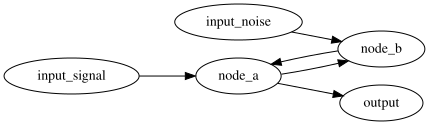

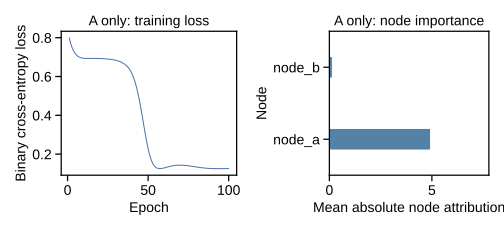

In [ ]:
display(graph_a_only)
plot_case_results("A only", result_a_only, attr_xlim)

### Case: both inputs informative

Both inputs carry class signal (`input_signal_a` → `node_a`,
`input_signal_b` → `node_b`). Both hidden nodes should receive
importance.


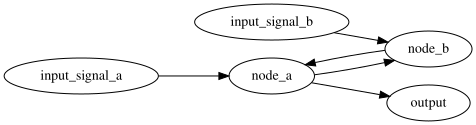

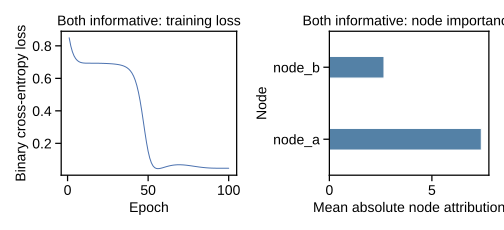

In [ ]:
display(graph_both)
plot_case_results(
    "Both informative",
    result_both,
    attr_xlim,
)

### Case: B only

Only the input to `node_b` (`input_signal`) is informative. The
input to `node_a` is `input_noise`. Because only `node_a`
connects to `output`, the signal can reach the output only along
the path
`input_signal → node_b → node_a → output`. Both hidden nodes
should therefore receive importance.


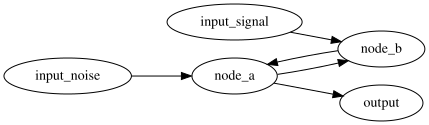

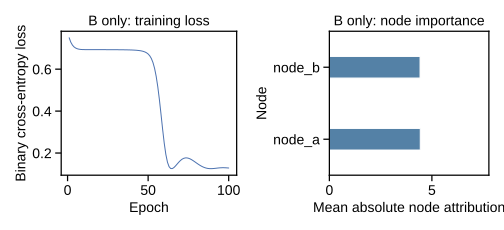

In [ ]:
display(graph_b_only)
plot_case_results("B only", result_b_only, attr_xlim)

### Case: neither input informative

Both inputs are uninformative (`input_noise_a`, `input_noise_b`).
The model should not recover strong, consistent importance on either
hidden node.


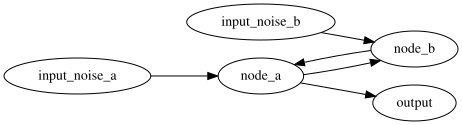

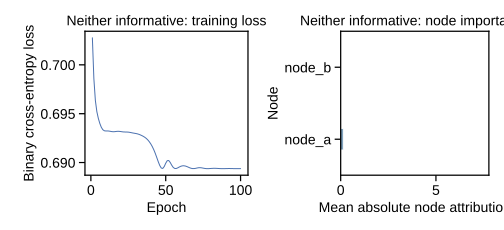

In [ ]:
display(graph_neither)
plot_case_results(
    "Neither informative",
    result_neither,
    attr_xlim,
)

### Control summary

Across the four cases:

- **A only** (`input_signal` / `input_noise`): importance concentrates
  on `node_a`; `node_b` stays low
- **Both** (`input_signal_a` / `input_signal_b`): both hidden nodes
  receive importance
- **B only** (`input_noise` → `node_a`, `input_signal` → `node_b`):
  loss decreases and both hidden nodes receive importance via the
  path `input_signal → node_b → node_a → output`
- **Neither** (`input_noise_a` / `input_noise_b`): loss remains near
  chance; neither hidden node shows strong recovered importance

A only and B only use the same architecture and step count. They
differ in which hidden node the informative input feeds. Low
importance on `node_b` in the A-only setting therefore reflects its
uninformative input, not an inability to score that node. With two
steps instead of three, the path `input → node_b → node_a → output`
would not fit, and `node_b` would score zero whatever its input.

## Feedback into a measured feature

In a [knowledge-primed neural network](../concepts/#kpnn), the input
nodes are measured genes. A feedback loop in the prior is a cycle in
the graph, and it often returns to one of those genes. Take a toy
prior: the transcription factor STAT3 and two of its target genes,
MYC and SOCS3.

Edges run in the direction of computation, as in every
[edgelist](../concepts/#edgelist): from the node whose value is read
to the node computed from it. For gene regulation, that is the reverse
of the arrow a biologist draws. A transcription factor regulates its
target genes, but the model reads the measured genes and computes the
factor from them, so the edge runs from gene to factor. The rows below
mean:

- `MYC → STAT3` and `SOCS3 → STAT3`: STAT3 induces these target
  genes.
- `STAT3 → SOCS3`: the feedback. Here SOCS3 is the regulator: the
  SOCS3 protein acts back on STAT3 and, in the cell, dampens STAT3
  activation, a negative feedback.

An edge carries no sign. The prior says which nodes interact, not
whether one activates or dampens the other; training learns the sign
of each weight.

With one node per gene, the edge `STAT3 → SOCS3` enters the node that
holds the SOCS3 measurement:

In [ ]:
merged_edgelist = pd.DataFrame(
    {
        "source": [
            "MYC",
            "SOCS3",
            "STAT3",
            "STAT3",
        ],
        "target": [
            "STAT3",
            "STAT3",
            "SOCS3",
            "output",
        ],
    }
)
merged_spec = kpnn2.parse_adjacency(merged_edgelist)

merged_spec.input_nodes, merged_spec.hidden_nodes

(('MYC',), ('SOCS3', 'STAT3'))

The node `SOCS3` has an incoming edge, so the parser makes it a
hidden node, and `MYC` is the only input. A column of measured SOCS3
expression named `SOCS3` makes `align_inputs()` raise, because the
model computes that node instead of reading it. Writing the
measurement into the `SOCS3` slot by hand does not help either:
`forward()` would write it in before every step, so the value that
`STAT3 → SOCS3` computes for `SOCS3` is overwritten before any node
reads it.

To keep the measurement and the cycle apart, use two nodes for SOCS3.
The input node `SOCS3_gene` holds the measured expression. `SOCS3` is
the model's node for SOCS3 on the cycle, computed from
`SOCS3_gene` and from `STAT3`. This is the naming rule of
[Node](../concepts/#node) on the Terminology page. `MYC` is not on a
cycle, so its measurement `MYC_gene` feeds `STAT3` directly. Only a
gene on a cycle needs the second node.

In [ ]:
split_edgelist = pd.DataFrame(
    {
        "source": [
            "MYC_gene",
            "SOCS3_gene",
            "SOCS3",
            "STAT3",
            "STAT3",
        ],
        "target": [
            "STAT3",
            "SOCS3",
            "STAT3",
            "SOCS3",
            "output",
        ],
    }
)
split_spec = kpnn2.parse_adjacency(split_edgelist)

split_spec.input_nodes, split_spec.hidden_nodes, split_spec.output_nodes

(('MYC_gene', 'SOCS3_gene'), ('SOCS3', 'STAT3'), ('output',))

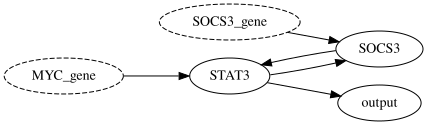

In [ ]:
split_drawing = Digraph()
split_drawing.attr(rankdir="LR")
for node_name in split_spec.input_nodes:
    split_drawing.node(
        node_name,
        node_name,
        style="dashed",
    )
for row in split_edgelist.itertuples(index=False):
    split_drawing.edge(
        str(row.source),
        str(row.target),
    )
split_drawing

Dashed nodes are the inputs. Both measurements, `MYC_gene` and
`SOCS3_gene`, are input nodes, so `align_inputs()` finds a column for
each, and the edge `STAT3 → SOCS3` enters `SOCS3`, not the
measurement. `SOCS3_gene` stays fixed, and `SOCS3` combines it with
the value from `STAT3` at every step.

The second node adds one edge to every path through `SOCS3`.
`SOCS3_gene → SOCS3 → STAT3 → output` is three edges long, and a lap
around `SOCS3 ⇄ STAT3` adds two. So `output` first holds a value
from `SOCS3_gene` after step 3, and first holds one that went once
around the cycle after step 5. Choose the step count from the longest
path the model should use.
[How a cycle runs](../unrolling-a-cycle/) traces how paths and steps
add up.

## Where to go next

- [Time-series example](../time-series-example/) writes a new `x_t`
  in at each step, so a self-loop carries state across a sequence.
- [Transformer example](../transformer-example/) uses the same
  packed indices as an attention allow-set.
- [Layered vs. unlayered](../layered_vs_adjacency/) compares this
  layout with `parse_layered()`.
- [PackedLinear](../packed_linear/) replaces `MaskedLinear` when
  the `(n, n)` square would strain RAM.